In [ ]:
import numpy as np

from alphagenome.data import genome
from alphagenome.models import dna_client
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.interpretation import ism
from alphagenome.models import dna_client
from alphagenome.models import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd
from tangermeme.ersatz import dinucleotide_shuffle
from tangermeme.utils import one_hot_encode, characters, random_one_hot
from tangermeme.marginalize import marginalize
from tangermeme.ersatz import substitute
import random
from tqdm import tqdm
import time
from alphagenome.data import gene_annotation, genome, track_data, transcript
from alphagenome.models import dna_client
from alphagenome.visualization import plot_components
from tangermeme.io import extract_loci
from tqdm.auto import tqdm
from tangermeme.ablate import ablate
from tangermeme.ersatz import dinucleotide_shuffle
import pandas as pd

/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.27.2 is exactly one major version older than the runtime version 6.31.1 at alphagenome/protos/dna_model.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.27.2 is exactly one major version older than the runtime version 6.31.1 at alphagenome/protos/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm a

Process to find OCT-SOX motifs

1. Find instances of OCT-SOX near peaks
2. ablate those and generate predictions before and after

In [3]:
# downloading cardiac fibroblast peaks
!wget https://www.encodeproject.org/files/ENCFF942AKV/@@download/ENCFF942AKV.bed.gz

E0000 00:00:1754331448.559446   22066 backup_poller.cc:139] Run client channel backup poller: UNKNOWN:pollset_work {children:[UNKNOWN:epoll_wait: Bad file descriptor (9)]}
--2025-08-04 18:17:28--  https://www.encodeproject.org/files/ENCFF942AKV/@@download/ENCFF942AKV.bed.gz
Resolving www.encodeproject.org (www.encodeproject.org)... 34.211.244.144
Connecting to www.encodeproject.org (www.encodeproject.org)|34.211.244.144|:443... connected.
HTTP request sent, awaiting response... 307 Temporary Redirect
Location: https://encode-public.s3.amazonaws.com/2021/02/08/101539d3-8a17-454a-a298-6d223dbc4bc7/ENCFF942AKV.bed.gz?response-content-disposition=attachment%3B%20filename%3DENCFF942AKV.bed.gz&AWSAccessKeyId=REDACTED&Signature=REDACTED&x-amz-security-token=REDACTED&Expires=1754461048 [following]
--2025-08-04 18:17:28--  https://encode-public.s3.amazonaws.com/2021/02/08/101539d3-8a17-454a-a298-6d223dbc4bc7/ENCFF942AKV.bed.gz?response-content-disposition=attachment%3B%20filename%3DENCFF942AKV.

In [3]:
import os
API_KEY = os.environ["ALPHAGENOME_API_KEY"]  # set: export ALPHAGENOME_API_KEY=...
dna_model = dna_client.create(API_KEY)

fibroblast_ontology = "CL:0002548"

In [1]:
oct_sox_hits = "/users/kobbad/feat_leakage/all_ap1_motifs/OCTSOX_FIMO_HITS/fimo.tsv"
cardiac_fibroblast_peaks = "/users/kobbad/feat_leakage/alphagenome/ENCFF942AKV.bed.gz"

fasta = "/oak/stanford/groups/akundaje/jmschr/common/hg38/hg38.fa"

oct_sox_hits = pd.read_csv(oct_sox_hits, sep='\t')
cardiac_fibroblast_peaks = pd.read_csv(cardiac_fibroblast_peaks, sep='\t', header=None)

NameError: name 'pd' is not defined

In [5]:
cardiac_fibroblast_peaks.shape, oct_sox_hits.shape

((234644, 10), (66176, 10))

In [6]:
oct_sox_hits.head()

,motif_id,motif_alt_id,sequence_name,start,stop,strand,score,p-value,q-value,matched_sequence
0,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chrUn_GL000195v1,46060.0,46072.0,-,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA
1,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr17_GL000205v2_random,101693.0,101705.0,-,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA
2,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr19_GL383575v2_alt,102517.0,102529.0,-,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA
3,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chrUn_GL000195v1,177018.0,177030.0,+,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA
4,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr19_GL383573v1_alt,177547.0,177559.0,-,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA


In [7]:
oct_sox_chroms = oct_sox_hits[oct_sox_hits.sequence_name.astype(str).apply(lambda x: len(x)<=5).values]
oct_sox_chroms.dropna(inplace=True)
oct_sox_chroms['start'] = oct_sox_chroms['start'].astype(int)
oct_sox_chroms['stop'] = oct_sox_chroms['stop'].astype(int)
oct_sox_chroms.reset_index(drop=True, inplace=True)
oct_sox_chroms.head()

oct_sox_chroms.shape

/tmp/ipykernel_63625/645416213.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  oct_sox_chroms.dropna(inplace=True)
/tmp/ipykernel_63625/645416213.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  oct_sox_chroms['start'] = oct_sox_chroms['start'].astype(int)
/tmp/ipykernel_63625/645416213.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a

(64256, 10)

In [8]:
peak_groups = {
    chrom: peaks[[1, 2, 9]].values # 9 is the peak summit
    for chrom, peaks in cardiac_fibroblast_peaks.groupby(0)
}

# Preallocate result arrays
closest_peak_start = []
closest_peak_end = []
closest_peak_distance = []

for row in tqdm(oct_sox_chroms.itertuples(), total=len(oct_sox_chroms)):
    chrom = row.sequence_name
    start = row.start
    end = row.stop

    if chrom not in peak_groups:
        closest_peak_start.append(None)
        closest_peak_end.append(None)
        closest_peak_distance.append(None)
        continue

    peaks = peak_groups[chrom]
    # Vectorized computation: distance to start or end of each peak
    distances = np.minimum(np.abs((peaks[:,0]+peaks[:,2]) - start), np.abs((peaks[:,0]+peaks[:,2]) - end))
    #distances = np.minimum(np.abs(peaks[:, 0] - start), np.abs(peaks[:, 1] - start))
    min_idx = np.argmin(distances)

    closest_peak_start.append(peaks[min_idx, 0])
    closest_peak_end.append(peaks[min_idx, 1])
    closest_peak_distance.append(distances[min_idx])


  0%|          | 0/64256 [00:00<?, ?it/s]

100%|██████████| 64256/64256 [00:02<00:00, 24676.10it/s]


In [9]:
oct_sox_chroms['closest_enhancer_start'] = closest_peak_start
oct_sox_chroms['closest_enhancer_end'] = closest_peak_end
oct_sox_chroms['distance'] = closest_peak_distance

oct_sox_chroms.head()

/tmp/ipykernel_63625/3246131437.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  oct_sox_chroms['closest_enhancer_start'] = closest_peak_start
/tmp/ipykernel_63625/3246131437.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  oct_sox_chroms['closest_enhancer_end'] = closest_peak_end
/tmp/ipykernel_63625/3246131437.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation:

,motif_id,motif_alt_id,sequence_name,start,stop,strand,score,p-value,q-value,matched_sequence,closest_enhancer_start,closest_enhancer_end,distance
0,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr9,2018958,2018970,+,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,2017800,2018080,1083
1,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr7,3281165,3281177,+,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,3282460,3282800,1358
2,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr12,3798659,3798671,+,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,3803980,3804140,5384
3,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr8,3908225,3908237,-,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,3284660,3284860,623490
4,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chrX,4530392,4530404,+,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,4547340,4547520,17011


In [10]:
oct_sox_chroms.distance.describe()

count    6.425600e+04
mean     4.318997e+04
std      2.926816e+05
min      0.000000e+00
25%      2.699000e+03
50%      8.102000e+03
75%      2.632700e+04
max      3.048168e+07
Name: distance, dtype: float64

In [11]:
# get oct-sox motif hits within 200-500 bp of the peak summit
filt_oct_sox_hits = oct_sox_chroms[(oct_sox_chroms.distance > 200) & (oct_sox_chroms.distance < 500)]

In [12]:
# confirming all the OCT-SOX hits are the same length
filt_oct_sox_hits.matched_sequence.astype(str).apply(lambda x: len(x)).value_counts()

matched_sequence
13    2375
Name: count, dtype: int64

In [13]:
filt_oct_sox_hits.head()

,motif_id,motif_alt_id,sequence_name,start,stop,strand,score,p-value,q-value,matched_sequence,closest_enhancer_start,closest_enhancer_end,distance
88,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr15,43881459,43881471,-,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,43880920,43881120,464
90,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr22,44608812,44608824,-,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,44609240,44609400,491
99,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr15,49610763,49610775,-,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,49610280,49610440,408
204,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chrX,115460003,115460015,-,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,115459640,115459780,288
236,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr3,154040816,154040828,-,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,154040400,154040580,341


In [ ]:
SEQ_LEN = 2048

OCT_SOX = "ATTGTTATGCAAAA"
SHUFFLED_OCT_SOX_ARRAY = dinucleotide_shuffle(one_hot_encode(OCT_SOX).unsqueeze(0)).squeeze()

# format bed file for extracting hits
hits = filt_oct_sox_hits.filter(['sequence_name','start','stop']).reset_index(drop=True)
hits = hits.rename(columns={'sequence_name':'chromosome'})
hits = hits.rename(columns={'stop':'end'})
hits = hits.astype({'start':'int','end':'int'})

loci = extract_loci(hits, fasta, in_window = SEQ_LEN, verbose=True)
OCT_SOX, SHUFFLED_OCT_SOX_ARRAY.shape

In [15]:
dna_seq = [characters(l) for l in loci]
len(dna_seq), hits.shape

dna_seq_subset = dna_seq[:400]

In [16]:
characters(loci[0])

'CTTGAAAGACGTTGCACCTGAACTCTCGCCTCCTGGAAACTAACCCATTCTTTACTTCCACAGGCTTGGTAGCCCCTGTACTGATAAAGCCATTTAATTGCTACAATCTTTTATTTATTTCCACATCCAAACCTGATGTCCATCTCCCTCTCCTCACCCTGAGCCTGTGAGGTTCATTTGGGCCAGGTCAGTTTTACCTGCGCTGTCCTGCATCTAATGGGTCCTGGGCTGGGGGCCATGACCAGGGCCACTTGCAGCCTTGGGCACAGGGTGTGAGAAGCACCTGGAAGTCTGCTGAGCTGTAACCTACCAAGTGTGCCATTCTATGAGGCTGGTTTTGAGGAAGTGCCCTGGCCCTAGGGGGCCTATACTCCTCAGCAGCCTCTCCCCACTGTACGTCTCTTTGCATTTGGCAGCAAGGGGGAATAGTTTGGACAAGGAACCTGCTGCTGCAATGGGAGGAGGAGGCTGGAGGTAAAGCCAGAGCTGAATGGGGACCTGACTCAGCCTCAGCATGTCTCAGGATCACAAGGACTGTTTTCCCCGCCTCTGAGTTGTTCTACTAACCCTACTTGGCAGCAACTCTCAGTGAGTTTTGTCTCTACACAGAGAGCCTCAGCCCTCCCTCTTTTGGGAATGCTGGTTTCCTGGACATTCTTCCCTGTTCTGGGAAGTAGGCATGCACAAGGCTCCTCTCCTGTTTTACATCCTGCATGGTGCTAGCTTCCCTAGGGTGAGCCTTTTGTTTGGGAGGACAGCTGTCCCAGCTCTCTGTGGAGGATGGGGATGGACCCTCTAGCTTCAGCCTCAGAGGGATGGAAAGAAAGGCCACAGAGGGGAGAAAGTTATGTTTCCTCAGAGAATTTCATTCTACTTCCTGAGATGTACACCCCAAAAGAGGGACGGAGAGAGCCAAGGGACAGTGAGAGCCAAGCTCAGTTCTCCGGGTCAGCCTAAGATGGGAGGAAACACCAGGAGGCTGTGTCTCATGATGGTCAT

In [17]:
hits.shape, filt_oct_sox_hits.shape

((2375, 3), (2375, 13))

In [18]:
results_before_ablation = dna_model.predict_sequences(
    sequences = dna_seq_subset,
    requested_outputs = [dna_client.OutputType.DNASE],
    ontology_terms=[fibroblast_ontology],
    progress_bar=True
)

  0%|          | 0/400 [00:00<?, ?it/s]

100%|██████████| 400/400 [00:11<00:00, 33.62it/s]


In [19]:
ablation_start = 2048 // 2 - 7
ablation_end = 2048 // 2 + 7

loci_ablated = dinucleotide_shuffle(loci, start = ablation_start, end = ablation_end, n=1).squeeze()

In [21]:
dna_seq_ablated = [characters(l) for l in loci_ablated]

dna_seq_subset_ablated = dna_seq_ablated[:400]

results_after_ablation = dna_model.predict_sequences(
    sequences = dna_seq_subset_ablated,
    requested_outputs = [dna_client.OutputType.DNASE],
    ontology_terms=[fibroblast_ontology],
    progress_bar=True
)

100%|██████████| 400/400 [00:10<00:00, 36.52it/s]


In [22]:
scores_ablated = np.array([r.dnase.values.sum() for r in results_after_ablation])
scores = np.array([r.dnase.values.sum() for r in results_before_ablation]) 

In [23]:
oct_sox_ablation_strength = scores_ablated - scores

In [24]:
np.argsort(oct_sox_ablation_strength)[::-1][:10]

array([ 87, 335,  99, 278, 251,  41,  85, 197, 234,  32])

(0.0, 14.85)

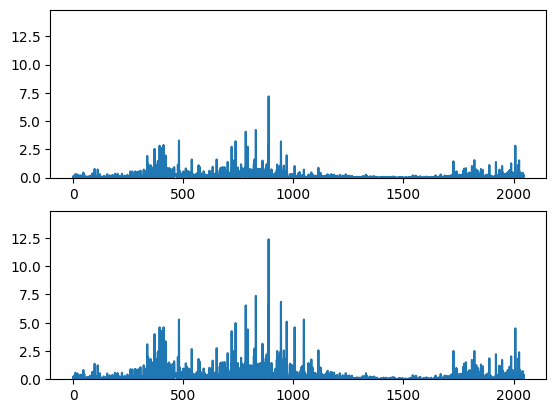

In [26]:
index = 87

fig, axs = plt.subplots(2 ,1)

before_ablation_profile = results_before_ablation[index].dnase.values.squeeze()
after_ablation_profile = results_after_ablation[index].dnase.values.squeeze()

max_value = 1.2 * np.max((before_ablation_profile.max().item(), after_ablation_profile.max().item())).item()

axs[0].plot(before_ablation_profile)
axs[0].set_ylim(0,max_value)

axs[1].plot(after_ablation_profile)
axs[1].set_ylim(0,max_value)

In [27]:
# index = 299 is OK, 87 is possibly best, 251 is ok
chrom, start, end = hits.iloc[index]
sequence_interval = genome.Interval(chrom, start, end)
sequence_interval = sequence_interval.resize(dna_client.SEQUENCE_LENGTH_2KB)
ism_interval = sequence_interval.resize(60)

dnase_variant_scorer = variant_scorers.CenterMaskScorer(
    requested_output=dna_client.OutputType.DNASE,
    width=2001,
    aggregation_type=variant_scorers.AggregationType.DIFF_MEAN,
)


In [28]:
variant_scores = dna_model.score_ism_variants(
    interval=sequence_interval,
    ism_interval=ism_interval,
    variant_scorers=[dnase_variant_scorer],
)

  0%|          | 0/6 [00:00<?, ?it/s]

100%|██████████| 6/6 [00:04<00:00,  1.41it/s]


In [29]:
def extract_fibroblast(adata):
  values = adata.X[:, adata.var['ontology_curie'] == fibroblast_ontology]
  assert values.size == 1
  return values.flatten()[0]

ism_result = ism.ism_matrix(
    [extract_fibroblast(x[0]) for x in variant_scores],
    variants=[v[0].uns['variant'] for v in variant_scores],
)

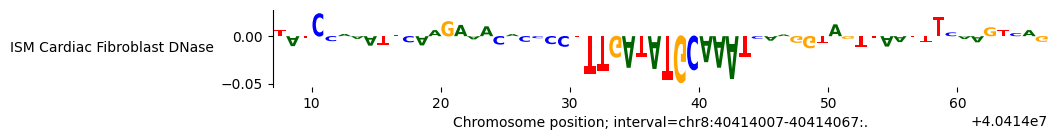

In [30]:
plot_components.plot(
    [
        plot_components.SeqLogo(
            scores=ism_result,
            scores_interval=ism_interval,
            ylabel='ISM Cardiac Fibroblast DNase',
        )
    ],
    interval=ism_interval,
    fig_width=10,
)

plt.show()

In [35]:
chrom, start, end = hits.iloc[87]
sequence_interval = genome.Interval(chrom, start, end)
sequence_interval = sequence_interval.resize(dna_client.SEQUENCE_LENGTH_100KB)
sequence_interval

Interval(chromosome='chr8', start=40348501, end=40479573, strand='.', name='')

In [53]:
# download cardiac fibroblast bigwig from Encode
!wget https://www.encodeproject.org/files/ENCFF424KBD/@@download/ENCFF424KBD.bigWig

--2025-08-06 16:45:47--  https://www.encodeproject.org/files/ENCFF424KBD/@@download/ENCFF424KBD.bigWig
Resolving www.encodeproject.org (www.encodeproject.org)... 34.211.244.144
Connecting to www.encodeproject.org (www.encodeproject.org)|34.211.244.144|:443... connected.
HTTP request sent, awaiting response... 307 Temporary Redirect
Location: https://encode-public.s3.amazonaws.com/2021/02/08/13616ba1-4739-4665-99fd-772c9bd2985a/ENCFF424KBD.bigWig?response-content-disposition=attachment%3B%20filename%3DENCFF424KBD.bigWig&AWSAccessKeyId=REDACTED&Signature=REDACTED&x-amz-security-token=REDACTED&Expires=1754628347 [following]
--2025-08-06 16:45:47--  https://encode-public.s3.amazonaws.com/2021/02/08/13616ba1-4739-4665-99fd-772c9bd2985a/ENCFF424KBD.bigWig?response-content-disposition=attachment%3B%20filename%3DENCFF424KBD.bigWig&AWSAccessKeyId=REDACTED&Signature=REDACTED&x-amz-security-token=REDACTED&Expires=1754628347
Resolving encode-public.s3.amazonaws.com (encode-public.s3.amazonaws.com)

In [36]:
# The GTF file contains information on the location of all trancripts.
# Note that we use genome assembly hg38 for human.
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)

# Set up transcript extractors using the information in the GTF file.
gtf_transcripts = gene_annotation.filter_protein_coding(gtf)
gtf_transcripts = gene_annotation.filter_to_longest_transcript(gtf_transcripts)
transcript_extractor = transcript_utils.TranscriptExtractor(gtf_transcripts)

In [37]:
output = dna_model.predict_interval(
    interval=sequence_interval,
    requested_outputs=[dna_client.OutputType.DNASE],
    ontology_terms=[fibroblast_ontology],
) 

output.dnase.values.shape

(131072, 1)

In [44]:
longest_transcripts = transcript_extractor.extract(sequence_interval)
print(f'Extracted {len(longest_transcripts)} transcripts in this interval.')

Extracted 0 transcripts in this interval.


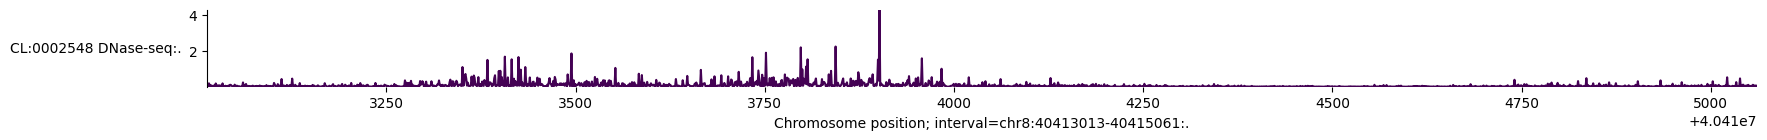

In [52]:
plot_components.plot(
    components=[
        plot_components.Tracks(output.dnase),
    ],
    interval=output.dnase.interval.resize(2048),
)

plt.show()

In [39]:
output.dnase.interval

Interval(chromosome='chr8', start=40348501, end=40479573, strand='.', name='')

In [51]:
output.dnase.interval.resize(1000)

Interval(chromosome='chr8', start=40413537, end=40414537, strand='.', name='')

In [47]:
output.dnase.interval

Interval(chromosome='chr8', start=40348501, end=40479573, strand='.', name='')

### Example locus

In [2]:
import os
API_KEY = os.environ["ALPHAGENOME_API_KEY"]  # set: export ALPHAGENOME_API_KEY=...
dna_model = dna_client.create(API_KEY)

fibroblast_ontology = "CL:0002548"

oct_sox_hits = "/users/kobbad/feat_leakage/all_ap1_motifs/OCTSOX_FIMO_HITS/fimo.tsv"
cardiac_fibroblast_peaks = "/users/kobbad/feat_leakage/alphagenome/ENCFF942AKV.bed.gz"

fasta = "/oak/stanford/groups/akundaje/jmschr/common/hg38/hg38.fa"

oct_sox_hits = pd.read_csv(oct_sox_hits, sep='\t')
cardiac_fibroblast_peaks = pd.read_csv(cardiac_fibroblast_peaks, sep='\t', header=None)

In [3]:
chrom, start, end = 'chr8', 40348501, 40479573

sequence_interval = genome.Interval(chrom, start, end)
sequence_interval = sequence_interval.resize(dna_client.SEQUENCE_LENGTH_2KB)
ism_interval = sequence_interval.resize(60)

dnase_variant_scorer = variant_scorers.CenterMaskScorer(
    requested_output=dna_client.OutputType.DNASE,
    width=2001,
    aggregation_type=variant_scorers.AggregationType.DIFF_MEAN,
)

variant_scores = dna_model.score_ism_variants(
    interval=sequence_interval,
    ism_interval=ism_interval,
    variant_scorers=[dnase_variant_scorer],
)

  0%|          | 0/6 [00:00<?, ?it/s]

100%|██████████| 6/6 [00:04<00:00,  1.46it/s]


In [4]:
def extract_fibroblast(adata):
  values = adata.X[:, adata.var['ontology_curie'] == fibroblast_ontology]
  assert values.size == 1
  return values.flatten()[0]

ism_result = ism.ism_matrix(
    [extract_fibroblast(x[0]) for x in variant_scores],
    variants=[v[0].uns['variant'] for v in variant_scores],
)

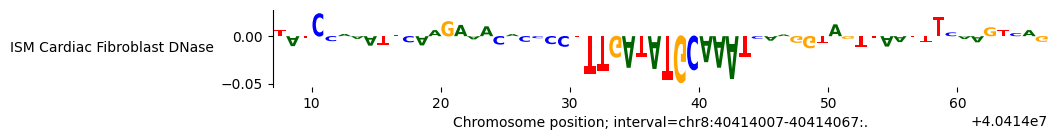

In [5]:
fig = plot_components.plot(
    [
        plot_components.SeqLogo(
            scores=ism_result,
            scores_interval=ism_interval,
            ylabel='ISM Cardiac Fibroblast DNase',
        )
    ],
    interval=ism_interval,
    fig_width=10,
)

# Save with the figure object
fig.savefig('seqlogo_plot.pdf', format='pdf', bbox_inches='tight', dpi=300)
fig.savefig('seqlogo_plot.svg', format='svg', bbox_inches='tight')

plt.show()

In [6]:
# The GTF file contains information on the location of all trancripts.
# Note that we use genome assembly hg38 for human.
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)

# Set up transcript extractors using the information in the GTF file.
gtf_transcripts = gene_annotation.filter_protein_coding(gtf)
gtf_transcripts = gene_annotation.filter_to_longest_transcript(gtf_transcripts)
transcript_extractor = transcript_utils.TranscriptExtractor(gtf_transcripts)

In [7]:
sequence_interval = sequence_interval.resize(dna_client.SEQUENCE_LENGTH_100KB)

output = dna_model.predict_interval(
    interval=sequence_interval,
    requested_outputs=[dna_client.OutputType.DNASE],
    ontology_terms=[fibroblast_ontology],
) 

output.dnase.values.shape

(131072, 1)

In [20]:
# get the actual accessibility profile

bigwig_file = "/users/kobbad/feat_leakage/alphagenome/ENCFF424KBD.bigWig"

_, actual_profile = extract_loci(pd.DataFrame({"chrom": [chrom], 
                                            "start": [start], 
                                            "end":[end]}, 
                                           index=None), 
                                           fasta, 
                                           signals=[bigwig_file],
                                           in_window = output.dnase.values.shape[0], 
                                           out_window=output.dnase.values.shape[0], 
                                           verbose=True)

actual_profile.shape

Loading Loci: 100%|██████████| 1/1 [00:00<00:00,  7.90it/s]


torch.Size([1, 1, 131072])

In [38]:
actual_values = actual_profile.squeeze().numpy()[:,np.newaxis]
actual_metadata = output.dnase.metadata.copy()
actual_metadata.loc[0,'name'] = 'actual'

actual_track_data = track_data.TrackData(actual_values,
                                         actual_metadata,
                                         interval = sequence_interval)

(131072, 1)

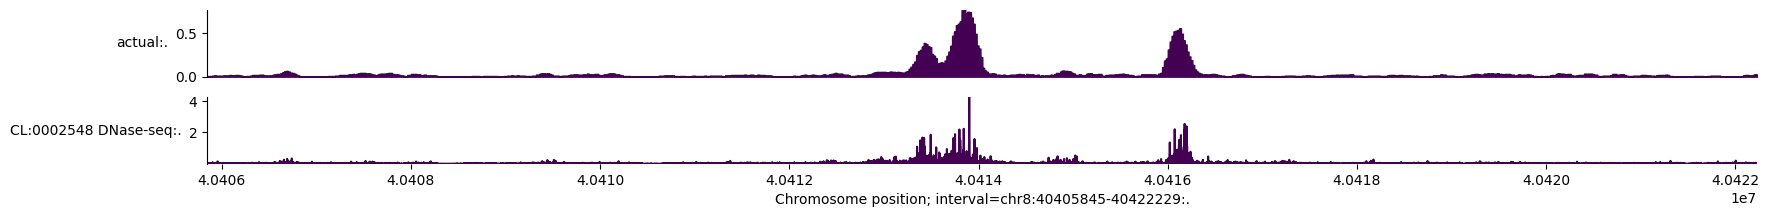

In [50]:
plot_components.plot(
    components=[
        plot_components.Tracks(actual_track_data, filled=True),
        plot_components.Tracks(output.dnase),
    ],
    interval=output.dnase.interval.resize(dna_client.SEQUENCE_LENGTH_16KB),
)
# Save as SVG
plt.savefig('trackplot.svg', format='svg', bbox_inches='tight')

# Save as PDF
plt.savefig('trackplot.pdf', format='pdf', bbox_inches='tight')

plt.show()

In [52]:
dna_client.SEQUENCE_LENGTH_16KB

16384